# Minimize RMS Spot Size — spherical 50 mm f/4 design

Competition: [Optiland community competition](https://www.optiland.org/competitions), ID `c14c84aa-2b25-48db-b488-d879d00d416a`.

This is a newly optimized six-element spherical prescription initialized from the [MIT-licensed public Optiland DoubleGauss sample](https://github.com/optiland/optiland/blob/a9e544a2e058f1c1b64606e9ce90e6dc103efee1/optiland/samples/objectives.py). The design below is frozen so it can be rebuilt and checked without access to a local project or data file.

The public page's linked Colab template was unavailable at preparation time (2026-11-10). The page does not define pupil density, numerical field weights, or the formula for P. **This notebook reports a reproducible local merit, not an official server score or ranking.** It uses field weights of one, equal spectral weights, an area-weighted circular pupil, and explicitly penalizes every listed constraint. The normalized mean objective is printed separately to avoid ambiguity about weight normalization.

Run all cells. Only public Optiland and ordinary Python packages are required. CUDA is not required to reproduce this notebook; the separate CPU/CUDA cross-check summary is included below.


In [1]:
import importlib.metadata, importlib.util, subprocess, sys

# Pin the exact public source revision used for the independent Optiland check.
revision = 'a9e544a2e058f1c1b64606e9ce90e6dc103efee1'
installed = importlib.metadata.version('optiland') if importlib.util.find_spec('optiland') else ''
if 'ga9e544a2' not in installed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'git+https://github.com/optiland/optiland.git@' + revision])

import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optiland.backend as be
from optiland.materials import Material, IdealMaterial
from optiland.materials.material_spec import MatchPolicy
from optiland.optic import Optic
from optiland.physical_apertures import RadialAperture
from optiland.rays import RealRays
be.set_backend('numpy')
print('Optiland:', importlib.metadata.version('optiland'))
print('NumPy:', np.__version__)


Optiland: 0.6.2.post234+ga9e544a2
NumPy: 2.3.5


## Search method: original standalone screening, then local RMS refinement

The search uses two explicitly different algorithms:

1. The **unchanged standalone-optics candidate generator and CPU/CUDA screening algorithm**, pinned below to its public source revision, samples 15 bounded micro-curvature candidates around a feasible six-element candidate. It ranks by worst RMS wavefront, mean wavefront and spot diagnostics, applies the same nominal solid policy to every candidate, verifies serial/parallel and CPU/CUDA agreement, and re-evaluates eight finalists plus the baseline with CPU 20×64 quadrature.
2. **SciPy bounded nonlinear least squares** refines spherical curvatures and axial spacings using standalone real-ray polychromatic RMS residuals, EFL and geometry guards. This refinement is not described as the repository's own search algorithm. A constraint-eligible candidate is retained only after the contest RMS audit below.

The following cell re-runs the actual original repository screening, not a reimplementation. It downloads only pinned public Python source files, verifies SHA-256, and operates only on the public synthetic candidate embedded here. The final frozen prescription is evaluated separately below.


In [2]:
source_payload=json.loads(r'''{
  "commit": "d130999165abc8ccc1865c4ef145cd6bda191a4d",
  "files": {
    "scripts/ai_zemax/__init__.py": "bded78d0cee5a6d576ad22817032e8d5eb32903f0683633c5e9b117c3015d7d5",
    "scripts/ai_zemax/standalone.py": "84e8b3f11775dc8ce133067cc2f94938493ffae852edcc155cfb4408a70d8fac",
    "scripts/ai_zemax/standalone_aberrations.py": "ee2b7dd9f0fe528448e557292e2fb9179c84bcdbfcf0ed674f8914b11a5e5f52",
    "scripts/ai_zemax/standalone_analysis.py": "ec5dfabc5ee6a1670e638b4bbf2e99479e013263c6423af73557b8906916224a",
    "scripts/ai_zemax/standalone_candidate_generation.py": "fa3264316a47c0cb3a54d4a6812193e86c904c16e56b38eb2f54538dd83a3335",
    "scripts/ai_zemax/standalone_cli.py": "7aa8ee9f4796137389bd3fbc7b89715ca25cf9e2f27b7d07b254f0d05a67cc1e",
    "scripts/ai_zemax/standalone_coupled_group_search.py": "8399516b597dd6ce991ba8775e6d15560b03ae73df5117f555b7e3a6a31a0764",
    "scripts/ai_zemax/standalone_demo.py": "73b4b7cbccebc7404c41e61a12f5a22440f4821c3c2c1a46ceeffe7e8ba10cdf",
    "scripts/ai_zemax/standalone_gpu_screen.py": "60d227a0f23688288e8c368880f12e5242864519fe1487cd85f3883f59436676",
    "scripts/ai_zemax/standalone_gpu_trace.py": "3aeb0d8b234635a24fa15fae74fa90e70ffb04a2353ea673368887f1ddb3f926",
    "scripts/ai_zemax/standalone_group_search.py": "94d3b15d2f06dd0e078a56241e61c7054577d6ed58c74be816ca3fb53a19efbd",
    "scripts/ai_zemax/standalone_manufacturing.py": "97ebf815911b88bd5b0d7de99390c8ee41b8b2972aaac122b9d5ee69063a5113",
    "scripts/ai_zemax/standalone_model.py": "26c82fe38588006b28d648961aa7dc825929c917fcee5065fa86ee890a44e3fb",
    "scripts/ai_zemax/standalone_mtf.py": "4212682c206e8acb31ae9ae12d5866d1b1e70d115672056367a9f5d0ce88fce9",
    "scripts/ai_zemax/standalone_mtf_geometric.py": "1ded7cc0fd3e75a7a3fbcd06d2bee7496403fa90eaa7bc6fa44bb2489b36b28b",
    "scripts/ai_zemax/standalone_mtf_workflow.py": "9c5b3f6ce43c70fe1ce8833f9062248c045bf2cf44d4e7f3fa0d9def402c20d4",
    "scripts/ai_zemax/standalone_optimization_cli.py": "9b8a54579e0e315941bbc905cc6adeb1631e4536f3616a01040357b8d3b1bf20",
    "scripts/ai_zemax/standalone_parallel_screen.py": "13fcb1e8e9d6b44b4d5ff510e9dc51f29c00e6eeef0423d0f0c064b898c7e827",
    "scripts/ai_zemax/standalone_plots.py": "d57fba66dc57b27be954e3b7f153cb13a6a279812851f1d2c81f1fee8d5e7160",
    "scripts/ai_zemax/standalone_seed_realize.py": "f2c6330527eff290dd5543719e753e56a9864549fbc9ba06d1c9fea41fce9074",
    "scripts/ai_zemax/standalone_seed_search.py": "c5d1fe334277fe82635525d9acf9a9953ddd4af33bae4f7bcc0da00d9ed9c577",
    "scripts/ai_zemax/standalone_spot.py": "d0d8171b8acf61639585a61896ed7e061ac15f4726af0434d3fe488a806c82d0",
    "scripts/ai_zemax/standalone_system.py": "54ef9eb7963e7153976b0dc6cd0701092ca44038ea8b7f04eb9b6c645f15b0bd"
  },
  "model": {
    "vertices_mm": [
      0.0,
      4.1713022245681355,
      4.271317074473588,
      10.979054452015319,
      13.319702043845771,
      20.787658156655503,
      26.64792501260648,
      29.269276187840024,
      35.19076159406879,
      35.29106233491684,
      38.16000087444962,
      71.7197223658496
    ],
    "surface_rows": [
      {
        "curvature_mm_inv": 0.03705714205899587,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 12.731595017631866,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.013483160266002858,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 12.731595017631866,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.050347432000094304,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 10.911501561172914,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.00032503983479604696,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 10.911501561172914,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.08685811011700643,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 10.911501561172914,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.0,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 4.224908396893084,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.07455108133142503,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 8.948727854973898,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.011039377203804353,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 8.948727854973898,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.05532310481022226,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 8.948727854973898,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.011909152443419049,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 10.01902079983143,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.024079225557293967,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 10.01902079983143,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.0,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 12.458413595178564,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      }
    ],
    "wavelengths_um": [
      0.486,
      0.588,
      0.656
    ],
    "wavelength_weights": [
      1.0,
      1.0,
      1.0
    ],
    "indices_by_wave": [
      [
        1.0,
        1.6304659372781796,
        1.0,
        1.6148700816641839,
        1.6146322406008868,
        1.0,
        1.0,
        1.6146322406008868,
        1.6275687230334062,
        1.0,
        1.6275687230334062,
        1.0,
        1.0
      ],
      [
        1.0,
        1.6222674943090845,
        1.0,
        1.6073567766564885,
        1.6033849729454086,
        1.0,
        1.0,
        1.6033849729454086,
        1.620386677937296,
        1.0,
        1.620386677937296,
        1.0,
        1.0
      ],
      [
        1.0,
        1.6187825443351676,
        1.0,
        1.604146457794088,
        1.5987609266116032,
        1.0,
        1.0,
        1.5987609266116032,
        1.617282365971793,
        1.0,
        1.617282365971793,
        1.0,
        1.0
      ]
    ],
    "fields": [
      [
        0.0,
        0.0
      ],
      [
        0.0,
        7.0
      ],
      [
        0.0,
        10.0
      ],
      [
        0.0,
        12.0
      ],
      [
        0.0,
        14.0
      ]
    ],
    "field_weights": [
      1.0,
      1.0,
      1.0,
      1.0,
      1.0
    ],
    "field_unit": "deg",
    "stop_surface": 6,
    "primary_wave": 1,
    "object_at_infinity": true,
    "field_type": "angle",
    "aperture_type": "enpd",
    "aperture_value": 12.5,
    "ray_aiming": "off",
    "gaussian_apodization": 0.0
  },
  "config": {
    "candidate_count": 15,
    "random_seed": 19,
    "curvature_variables": [
      {
        "surface": 1,
        "min_delta_mm_inv": -1e-06,
        "max_delta_mm_inv": 1e-06
      },
      {
        "surface": 3,
        "min_delta_mm_inv": -1e-06,
        "max_delta_mm_inv": 1e-06
      },
      {
        "surface": 11,
        "min_delta_mm_inv": -1e-06,
        "max_delta_mm_inv": 1e-06
      }
    ],
    "screening": {
      "manufacturing_policy": {
        "schema_version": 1,
        "policy_id": "contest1-nominal-sphere",
        "all_spherical": true,
        "sources": [
          "https://www.optiland.org/competitions"
        ],
        "notes": [
          "Mechanical radii equal declared lens radii; exact full-pupil envelope plus0.15mm design allocation.",
          "Nominal contest geometry only; separate final contest audit checks all numerical rules."
        ],
        "radial_samples": 1025,
        "surfaces": {
          "1": {
            "clear_radius_mm": 12.731595017631866,
            "mechanical_radius_mm": 12.731595017631866
          },
          "2": {
            "clear_radius_mm": 12.731595017631866,
            "mechanical_radius_mm": 12.731595017631866
          },
          "3": {
            "clear_radius_mm": 10.911501561172914,
            "mechanical_radius_mm": 10.911501561172914
          },
          "4": {
            "clear_radius_mm": 10.911501561172914,
            "mechanical_radius_mm": 10.911501561172914
          },
          "5": {
            "clear_radius_mm": 10.911501561172914,
            "mechanical_radius_mm": 10.911501561172914
          },
          "6": {
            "clear_radius_mm": 4.224908396893084,
            "mechanical_radius_mm": 4.224908396893084
          },
          "7": {
            "clear_radius_mm": 8.948727854973898,
            "mechanical_radius_mm": 8.948727854973898
          },
          "8": {
            "clear_radius_mm": 8.948727854973898,
            "mechanical_radius_mm": 8.948727854973898
          },
          "9": {
            "clear_radius_mm": 8.948727854973898,
            "mechanical_radius_mm": 8.948727854973898
          },
          "10": {
            "clear_radius_mm": 10.01902079983143,
            "mechanical_radius_mm": 10.01902079983143
          },
          "11": {
            "clear_radius_mm": 10.01902079983143,
            "mechanical_radius_mm": 10.01902079983143
          },
          "12": {
            "clear_radius_mm": 12.458413595178564,
            "mechanical_radius_mm": 12.458413595178564
          }
        },
        "lenses": [
          {
            "front_surface": 1,
            "rear_surface": 2
          },
          {
            "front_surface": 3,
            "rear_surface": 4
          },
          {
            "front_surface": 4,
            "rear_surface": 5
          },
          {
            "front_surface": 7,
            "rear_surface": 8
          },
          {
            "front_surface": 8,
            "rear_surface": 9
          },
          {
            "front_surface": 10,
            "rear_surface": 11
          }
        ],
        "defaults": {
          "minimum_center_thickness_mm": 2.0,
          "minimum_radial_thickness_mm": 1.0,
          "minimum_air_gap_mm": 0.0,
          "minimum_rim_gap_mm": 0.0,
          "minimum_clear_to_mechanical_radial_margin_mm": 0.0
        }
      }
    }
  }
}''')

import hashlib, os, tempfile, urllib.request
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

with tempfile.TemporaryDirectory(prefix='public-optics-screen-') as directory:
    work=Path(directory);scripts=work/'repo'/'scripts'
    def fetch_file(item):
        relative,expected=item
        url='https://raw.githubusercontent.com/wufansaber/standalone-optics/'+source_payload['commit']+'/'+relative
        data=urllib.request.urlopen(url,timeout=45).read()
        if hashlib.sha256(data).hexdigest()!=expected:raise RuntimeError('Source hash mismatch: '+relative)
        target=work/'repo'/relative;target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(data)
    with ThreadPoolExecutor(max_workers=6) as executor:list(executor.map(fetch_file,source_payload['files'].items()))
    (work/'model.json').write_text(json.dumps(source_payload['model']),encoding='utf8')
    (work/'config.json').write_text(json.dumps(source_payload['config']),encoding='utf8')
    runner=work/'run_screen.py'
    runner.write_text(chr(10).join(["from ai_zemax.standalone_optimization_cli import main",
        "if __name__=='__main__':","    raise SystemExit(main())",""]),encoding='utf8')
    env=dict(os.environ,PYTHONPATH=str(scripts),CUPY_CACHE_DIR=str(work/'cuda-cache'))
    def screen(backend):
        out=work/(backend+'.json')
        command=[sys.executable,str(runner),'screen','--model',str(work/'model.json'),
            '--config',str(work/'config.json'),'--backend',backend,'--workers','4',
            '--radial','6','--azimuthal','24','--dense-top','8','--verify-serial','--out',str(out)]
        completed=subprocess.run(command,env=env,check=True,capture_output=True,text=True,timeout=180)
        return json.loads(out.read_text(encoding='utf8'))
    source_cpu=screen('cpu')
    source_screen_summary={'sourceRevision':source_payload['commit'],
        'candidateCount':source_cpu['coarse']['candidate_count'],
        'serialParallelIdentical':source_cpu['timing']['serial_parallel_scores_identical'],
        'coarseRank':source_cpu['coarse']['ranked'],'denseRank':source_cpu['dense']['ranked'],
        'bestWavefrontCandidate':source_cpu['best_id'],'cpuTiming':source_cpu['timing']}
    try:
        import cupy as cp
        gpu_available=cp.cuda.runtime.getDeviceCount()>0
    except Exception:
        gpu_available=False
    if gpu_available:
        source_cuda=screen('cuda')
        source_screen_summary['cudaVerification']=source_cuda['timing']['cuda_verification']
        source_screen_summary['cpuCudaDenseRankIdentical']=source_cpu['dense']['ranked']==source_cuda['dense']['ranked']
        source_screen_summary['cudaTiming']=source_cuda['timing']
    else:
        source_screen_summary['cudaRerun']='No CUDA device/runtime available; CPU reproduction completed. Saved CUDA check is shown at the end.'
print(json.dumps(source_screen_summary,indent=2))


{
  "sourceRevision": "d130999165abc8ccc1865c4ef145cd6bda191a4d",
  "candidateCount": 15,
  "serialParallelIdentical": true,
  "coarseRank": [
    "candidate_00001",
    "candidate_00008",
    "candidate_00009",
    "candidate_00003",
    "candidate_00013",
    "candidate_00010",
    "candidate_00006",
    "candidate_00007",
    "baseline",
    "candidate_00011",
    "candidate_00005",
    "candidate_00004",
    "candidate_00002",
    "candidate_00014",
    "candidate_00012"
  ],
  "denseRank": [
    "candidate_00001",
    "candidate_00008",
    "candidate_00009",
    "candidate_00003",
    "candidate_00013",
    "candidate_00010",
    "candidate_00006",
    "candidate_00007",
    "baseline"
  ],
  "bestWavefrontCandidate": "candidate_00001",
  "cpuTiming": {
    "coarse_backend": "cpu",
    "serial_seconds": 1.1607437999991816,
    "pool_start_and_warmup_seconds": 0.5594249999994645,
    "coarse_seconds": 0.3653779999986,
    "serial_parallel_scores_identical": true,
    "warmed_speed

,id,type,radius,thickness,material,semiDiameter
0,0,object,NaN,NaN,AIR,6.250000
1,1,standard,26.982546,4.165277,SCHOTT:N-SSK2,12.735551
2,2,standard,74.080833,0.100073,AIR,12.735551
3,3,standard,19.852804,6.703278,SCHOTT:N-SK2,10.916260
4,4,standard,2159.737145,2.340554,SCHOTT:F5,10.916260
5,5,standard,11.506722,7.484759,AIR,10.916260
6,6,stop,NaN,5.858761,AIR,4.226468
7,7,standard,-13.418307,2.621327,SCHOTT:F5,8.948034
8,8,standard,90.138965,5.918862,SCHOTT:N-SK16,8.948034
9,9,standard,-18.068307,0.100297,AIR,8.948034


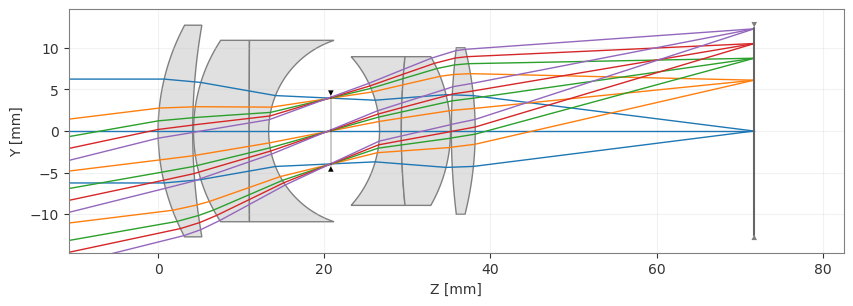

In [3]:
project = json.loads(r'''{
  "schemaVersion": 1,
  "name": "Spherical Six-Element 50 mm f4 · Standalone WFE Screen and RMS Refinement",
  "objectAtInfinity": true,
  "fieldType": "angle",
  "aperture": 12.5,
  "primaryWavelength": 1,
  "fields": [
    0.0,
    7.0,
    10.0,
    12.0,
    14.0
  ],
  "wavelengths": [
    {
      "value": 486.0,
      "weight": 1.0
    },
    {
      "value": 588.0,
      "weight": 1.0
    },
    {
      "value": 656.0,
      "weight": 1.0
    }
  ],
  "analysis": {
    "mtfSamples": 64
  },
  "rayAiming": {
    "mode": "off"
  },
  "description": "Public-gallery initialization, new contest optimization. No private prescription used.",
  "surfaces": [
    {
      "id": 0,
      "type": "object",
      "radius": null,
      "thickness": null,
      "material": "AIR",
      "semiDiameter": 6.25,
      "conic": 0.0,
      "asphere": [],
      "surfaceType": "STANDARD"
    },
    {
      "id": 1,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": 26.98254581303363,
      "thickness": 4.165277088671429,
      "material": "SCHOTT:N-SSK2",
      "semiDiameter": 12.735550876402655,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 2,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": 74.0808330503839,
      "thickness": 0.10007326904608795,
      "material": "AIR",
      "semiDiameter": 12.735550876402655,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 3,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": 19.85280362048218,
      "thickness": 6.703277843541189,
      "material": "SCHOTT:N-SK2",
      "semiDiameter": 10.916259651163829,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 4,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": 2159.7371454642116,
      "thickness": 2.340554049998131,
      "material": "SCHOTT:F5",
      "semiDiameter": 10.916259651163829,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 5,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": 11.506722475911006,
      "thickness": 7.484758921278743,
      "material": "AIR",
      "semiDiameter": 10.916259651163829,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 6,
      "type": "stop",
      "surfaceType": "STANDARD",
      "radius": null,
      "thickness": 5.858761326231504,
      "material": "AIR",
      "semiDiameter": 4.226468033887575,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 7,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": -13.418306647203437,
      "thickness": 2.6213266930885877,
      "material": "SCHOTT:F5",
      "semiDiameter": 8.948034251132755,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 8,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": 90.138965253226,
      "thickness": 5.918861878734615,
      "material": "SCHOTT:N-SK16",
      "semiDiameter": 8.948034251132755,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 9,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": -18.068307055331896,
      "thickness": 0.10029710426575336,
      "material": "AIR",
      "semiDiameter": 8.948034251132755,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 10,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": 84.03225946273947,
      "thickness": 2.8755564429748333,
      "material": "SCHOTT:N-SK16",
      "semiDiameter": 10.018745492440974,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 11,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": -41.546566077323554,
      "thickness": 33.578527372475364,
      "material": "AIR",
      "semiDiameter": 10.018745492440974,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    },
    {
      "id": 12,
      "type": "image",
      "surfaceType": "STANDARD",
      "radius": null,
      "thickness": 0.0,
      "material": "AIR",
      "semiDiameter": 12.45812962674468,
      "conic": 0.0,
      "asphere": [],
      "comment": "Public contest candidate"
    }
  ],
  "fieldDefinitions": [
    {
      "x": 0.0,
      "y": 0.0,
      "weight": 1.0
    },
    {
      "x": 0.0,
      "y": 7.0,
      "weight": 1.0
    },
    {
      "x": 0.0,
      "y": 10.0,
      "weight": 1.0
    },
    {
      "x": 0.0,
      "y": 12.0,
      "weight": 1.0
    },
    {
      "x": 0.0,
      "y": 14.0,
      "weight": 1.0
    }
  ],
  "fieldWeights": [
    1.0,
    1.0,
    1.0,
    1.0,
    1.0
  ],
  "fieldUnit": "deg",
  "apertureType": "enpd",
  "apertureValue": 12.5,
  "apodization": {
    "type": "uniform",
    "factor": 0.0
  },
  "objectDistance": null
}''')

def build_lens(p):
    lens=Optic(name=p['name'])
    lens.surfaces.add(index=0,thickness=float('inf'))
    for i,s in enumerate(p['surfaces'][1:],1):
        material=IdealMaterial(1.) if s['material']=='AIR' else Material(
            s['material'].split(':')[1],catalog=s['material'].split(':')[0].lower(),match_policy=MatchPolicy.STRICT)
        lens.surfaces.add(index=i,radius=np.inf if s['radius'] is None else s['radius'],
            thickness=s['thickness'],material=material,is_stop=s['type']=='stop',
            conic=s['conic'],aperture=RadialAperture(s['semiDiameter']))
        lens.surfaces[-1].set_semi_aperture(s['semiDiameter'])
    lens.set_aperture(aperture_type='EPD',value=p['aperture'])
    lens.fields.set_type('angle')
    for f in p['fields']:lens.fields.add(y=f)
    for i,w in enumerate(p['wavelengths']):lens.wavelengths.add(
        value=w['value']/1000,weight=w['weight'],is_primary=i==p['primaryWavelength'])
    return lens

lens=build_lens(project)
display(pd.DataFrame(project['surfaces'])[['id','type','radius','thickness','material','semiDiameter']])
fig,ax=lens.draw(num_rays=3,show=False,figsize=(10,4))
plt.show()


## Reproducible local evaluation

Geometry is in mm; wavelengths are 486/588/656 nm with equal weights. The five semi-fields are 0/7/10/12/14 degrees. A 20×96 Gauss–Legendre unit-disk quadrature traces 1,920 rays per field and wavelength, 28,800 total. Polychromatic RMS is measured about the combined spectral centroid, retaining lateral color. No failed ray is discarded for scoring.

Distortion uses the primary EFL f-tan reference at every field and every wavelength; the axial limit is sampled at 10⁻⁵ degrees. This is stricter than checking only the primary wavelength. The declared clear radii also define the nominal mechanical radius for the thickness audit; each cemented compound shares one outer radius. All spherical thickness and air-clearance extrema are checked at the radial endpoints, whose ordering is monotonic for the common spherical branches.

P sums squared normalized excesses: 100×(excess/constraint scale)² for numerical limits and 10⁶ for each structural violation. The scales are 0.5 mm EFL, 0.08 F-number, 2% distortion, 10 mm BFD, 80 mm track, 2 mm CT, 1 mm ET. Complete pupil transmission and non-overlapping nominal solids are additional gates. This is a nominal contest audit, not a fabrication/tolerance certification.


In [4]:
def disk_quadrature(radial_order=20,azimuths=96):
    x,w=np.polynomial.legendre.leggauss(radial_order)
    r=np.sqrt((x+1)/2)
    angle=2*np.pi*np.arange(azimuths)/azimuths
    pupil=np.stack((r[:,None]*np.cos(angle),r[:,None]*np.sin(angle)),axis=-1).reshape(-1,2)
    return pupil,np.repeat(w/(2*azimuths),azimuths)

rows=project['surfaces'][1:]
vertices=np.r_[0.,np.cumsum([s['thickness'] for s in rows[:-1]])]
indices=np.array([[1.]+[float(np.asarray(s.material_post.n(w['value']/1000)).item())
                         for s in lens.surfaces.surfaces[1:]] for w in project['wavelengths']])
stop=next(i for i,s in enumerate(project['surfaces']) if s['type']=='stop')

def transfer(wave,count):
    matrix=np.eye(2);z=0.;n=1.
    for i in range(count):
        s=rows[i];gap=vertices[i]-z
        matrix=np.array([[1.,gap/n],[0.,1.]])@matrix
        after=indices[wave,i+1];curvature=0. if s['radius'] is None else 1/s['radius']
        matrix=np.array([[1.,0.],[-(after-n)*curvature,1.]])@matrix
        z,n=vertices[i],after
    return matrix

primary=project['primaryWavelength']
matrix=transfer(primary,len(rows)-1)
efl=-indices[primary,-1]/matrix[1,0]
entrance=transfer(primary,stop)
entrance_pupil_z=entrance[0,1]/entrance[0,0]

def trace_field(field_deg,wave,pupil):
    slope=np.array([0.,np.tan(np.deg2rad(field_deg))])
    direction=np.r_[slope,1.];direction/=np.linalg.norm(direction)
    xy=project['aperture']/2*pupil-entrance_pupil_z*slope
    origin=np.c_[xy-30*slope,np.full(len(pupil),-30.)]
    rays=RealRays(origin[:,0],origin[:,1],origin[:,2],np.full(len(pupil),direction[0]),
                  np.full(len(pupil),direction[1]),np.full(len(pupil),direction[2]),
                  np.ones(len(pupil)),np.full(len(pupil),project['wavelengths'][wave]['value']/1000))
    lens.surfaces.trace(rays,skip=1,record=False)
    point=np.c_[rays.x,rays.y,rays.z]
    valid=(np.asarray(rays.i)>0)&np.isfinite(point).all(axis=1)
    return point,valid

pupil,weights=disk_quadrature()
rms_rows=[];full_transmission=True
for field in project['fields']:
    points=[]
    for wave in range(3):
        point,valid=trace_field(field,wave,pupil)
        full_transmission=full_transmission and bool(valid.all())
        if not valid.all():raise RuntimeError('Invalid pupil: candidate cannot score by losing rays.')
        points.append(point[:,:2])
    xy=np.concatenate(points);q=np.tile(weights/3,3)
    offset=xy-xy[0];offset-=q@offset
    rms=1000*np.sqrt(q@np.sum(offset*offset,axis=1))
    rms_rows.append({'fieldDeg':field,'rmsUm':float(rms)})
distortion=[]
for field in project['fields']:
    probe=field if field else 1e-5
    for wave,w in enumerate(project['wavelengths']):
        point,valid=trace_field(probe,wave,np.zeros((1,2)))
        if not valid[0]:raise RuntimeError('Invalid distortion chief.')
        ideal=efl*np.tan(np.deg2rad(probe))
        distortion.append({'fieldDeg':field,'wavelengthNm':w['value'],
                           'percent':float(100*(point[0,1]-ideal)/ideal)})
display(pd.DataFrame(rms_rows))
display(pd.DataFrame(distortion))
print('Optiland EFL / mm:',float(np.asarray(lens.paraxial.f2()).item()))
print('Independent ABCD EFL / mm:',efl)


,fieldDeg,rmsUm
0,0.0,2.000959
1,7.0,1.977490
2,10.0,1.911131
3,12.0,1.629911
4,14.0,2.500481


,fieldDeg,wavelengthNm,percent
0,0.0,486.0,-0.058029
1,0.0,588.0,-0.072300
2,0.0,656.0,-0.077087
3,7.0,486.0,-0.337528
4,7.0,588.0,-0.348772
5,7.0,656.0,-0.351919
6,10.0,486.0,-0.648649
7,10.0,588.0,-0.656418
8,10.0,656.0,-0.657702
9,12.0,486.0,-0.934960


Optiland EFL / mm: 50.000012165866565
Independent ABCD EFL / mm: 50.00001216586654


In [5]:
def sag(surface,radius):
    c=0. if surface['radius'] is None else 1/surface['radius']
    d=1-c*c*radius*radius
    if d<=0:raise ValueError('Spherical domain is invalid at the declared radius.')
    return c*radius*radius/(1+math.sqrt(d))

def audit(p,efl_value,distortion_rows,transmitted):
    checks=[]
    def gate(name,value,low=None,high=None,scale=1.,condition=None):
        violation=float(not condition) if condition is not None else max(
            0.,low-value if low is not None else 0.,value-high if high is not None else 0.)
        checks.append({'constraint':name,'value':value,'minimum':low,'maximum':high,
                       'passed':violation<=1e-10,'penalty':(1e6 if condition is not None else 100)*(violation/scale)**2})
    s=p['surfaces'];z=np.r_[0.,np.cumsum([row['thickness'] for row in s[1:-1]])]
    pairs=[(i,i+1) for i in range(1,len(s)-1) if s[i]['material']!='AIR']
    first=min(a for a,b in pairs);last=max(b for a,b in pairs)
    gate('Object at infinity',p['objectAtInfinity'],condition=p['objectAtInfinity'])
    gate('EFL / mm',efl_value,49.5,50.5,.5)
    gate('F-number',efl_value/p['aperture'],3.92,4.08,.08)
    gate('Elements',len(pairs),3,6)
    sphere=all(not row.get('conic') and not any(row.get('asphere',[])) and row.get('surfaceType','STANDARD')=='STANDARD' for row in s)
    gate('Spherical only',sphere,condition=sphere)
    stop_number=next(i for i,row in enumerate(s) if row['type']=='stop')
    gate('Stop within system',stop_number,condition=first<=stop_number<=last)
    gate('Supported catalog materials',True,condition=True) # Strict Material lookup already succeeded.
    gate('BFD / mm',float(z[-1]-z[last-1]),10.,scale=10.)
    gate('Track / mm',float(z[-1]-z[first-1]),high=80.,scale=80.)
    f_ok=p['fieldType']=='angle' and p['fields']==[0.,7.,10.,12.,14.] and all(r['x']==0 and r['weight']==1 for r in p['fieldDefinitions'])
    gate('Specified fields / equal weights',f_ok,condition=f_ok)
    w_ok=[w['value'] for w in p['wavelengths']]==[486.,588.,656.] and all(w['weight']==1 for w in p['wavelengths'])
    gate('Specified spectrum / equal weights',w_ok,condition=w_ok)
    for row in distortion_rows:
        gate('Distortion % at '+str(row['fieldDeg'])+' deg / '+str(row['wavelengthNm'])+' nm',abs(row['percent']),high=2.,scale=2.)
    for a,b in pairs:
        radius=max(s[a]['semiDiameter'],s[b]['semiDiameter']);ct=float(z[b-1]-z[a-1])
        et=ct+sag(s[b],radius)-sag(s[a],radius)
        gate('CT element '+str(a)+'-'+str(b)+' / mm',ct,2.,scale=2.)
        gate('ET element '+str(a)+'-'+str(b)+' / mm',et,1.)
    for prev,nxt in zip(pairs,pairs[1:]):
        if prev[1]==nxt[0]:continue
        b,a=prev[1],nxt[0]
        radius=min(max(s[i]['semiDiameter'] for i in prev),max(s[i]['semiDiameter'] for i in nxt))
        gap=float(z[a-1]-z[b-1]);minimum=min(gap,gap+sag(s[a],radius)-sag(s[b],radius))
        gate('Extra nominal air clearance '+str(b)+'-'+str(a)+' / mm',minimum,0.,scale=.1)
    gate('Complete sampled pupil',transmitted,condition=transmitted)
    return checks

checks=audit(project,efl,distortion,full_transmission)
P=sum(row['penalty'] for row in checks)
objective=sum((row['rmsUm']/25)**2 for row in rms_rows)
M=objective+P
display(pd.DataFrame(checks))
print(json.dumps({'allConstraintsPassed':all(row['passed'] for row in checks),
                  'objective_sum_equal_weights':objective,'objective_normalized_mean':objective/5,
                  'P':P,'local_M_not_official_score':M},indent=2))
assert all(row['passed'] for row in checks), 'Candidate is not eligible: one or more hard constraints failed.'
# Penalty sanity check: an EFL violation must never receive a zero penalty.
assert sum(row['penalty'] for row in audit(project,48.,distortion,full_transmission))>0


,constraint,value,minimum,maximum,passed,penalty
0,Object at infinity,True,NaN,NaN,True,0.0
1,EFL / mm,50.000012,49.50,50.50,True,0.0
2,F-number,4.000001,3.92,4.08,True,0.0
3,Elements,6,3.00,6.00,True,0.0
4,Spherical only,True,NaN,NaN,True,0.0
5,Stop within system,6,NaN,NaN,True,0.0
6,Supported catalog materials,True,NaN,NaN,True,0.0
7,BFD / mm,33.578527,10.00,NaN,True,0.0
8,Track / mm,71.747272,NaN,80.00,True,0.0
9,Specified fields / equal weights,True,NaN,NaN,True,0.0


{
  "allConstraintsPassed": true,
  "objective_sum_equal_weights": 0.032761180321418414,
  "objective_normalized_mean": 0.006552236064283683,
  "P": 0.0,
  "local_M_not_official_score": 0.032761180321418414
}


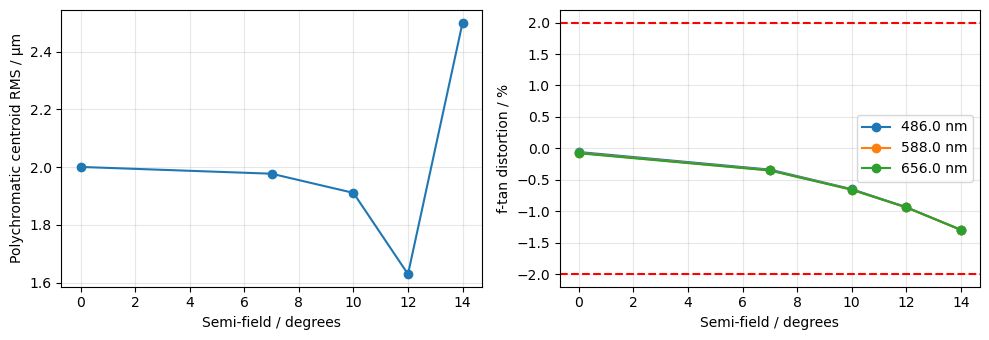

In [6]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].plot([r['fieldDeg'] for r in rms_rows],[r['rmsUm'] for r in rms_rows],'o-')
axes[0].set(xlabel='Semi-field / degrees',ylabel='Polychromatic centroid RMS / µm')
for w in [486.,588.,656.]:
    selected=[r for r in distortion if r['wavelengthNm']==w]
    axes[1].plot([r['fieldDeg'] for r in selected],[r['percent'] for r in selected],'o-',label=str(w)+' nm')
axes[1].axhline(2,color='r',linestyle='--');axes[1].axhline(-2,color='r',linestyle='--')
axes[1].set(xlabel='Semi-field / degrees',ylabel='f-tan distortion / %');axes[1].legend()
for ax in axes:ax.grid(True,alpha=.3)
fig.tight_layout();plt.show()


## Independent verification and limits

The local development run used four independent CPU optimization processes and an unmodified standalone-optics ray tracer, with float64 NumPy/Numba evaluation. The 20×96 final check matched independent Optiland catalog-material traces and a real CUDA/CuPy double-precision batch (no fast math). These are recorded measured checks, not a claim that CUDA is faster for every batch. CUDA is optional; the cells above independently re-evaluate the frozen lens in Optiland on CPU.

Changing pupil resolution from 12×64 to 20×96 changed the local merit only at numerical roundoff for this smooth spherical system. That comparison is not a proof of all unsampled field/wavelength performance. Distortion is additionally checked at all three colors. The smallest nominal edge-thickness margin is about 0.050 mm; tolerances, mounting, procurement and coatings require separate engineering work.

The following is a saved aggregate verification record from the development run. It is supplementary to the freshly computed Optiland outputs above.


In [7]:
verification_record = json.loads(r'''{
  "sampling": {
    "method": "Gauss-Legendre unit disk",
    "radialOrder": 20,
    "azimuths": 96,
    "raysPerFieldPerWavelength": 1920,
    "spectralWeights": "equal",
    "fieldWeights": "one each"
  },
  "cpu": {
    "workers": 4,
    "elapsedSeconds": 0.1978183999999601
  },
  "optiland": {
    "scope": "Optiland catalog material + independent intersection/refraction, identical explicit pupil rays",
    "allValidMasksMatch": true,
    "maxInterceptDifferenceMm": 5.861977570020827e-14,
    "rms": [
      {
        "fieldDeg": 0.0,
        "rmsUm": 2.0009588030052865
      },
      {
        "fieldDeg": 7.0,
        "rmsUm": 1.9774896487773328
      },
      {
        "fieldDeg": 10.0,
        "rmsUm": 1.9111310399053656
      },
      {
        "fieldDeg": 12.0,
        "rmsUm": 1.6299110010032882
      },
      {
        "fieldDeg": 14.0,
        "rmsUm": 2.500480860886069
      }
    ],
    "maxRmsDifferenceUm": 1.9624302183274267e-12,
    "localMerit": 0.032761180321415506
  },
  "cuda": {
    "groups": 15,
    "rays": 28800,
    "allValidMasksMatch": true,
    "maxInterceptDifferenceMm": 0.0,
    "maxDirectionDifference": 0.0,
    "elapsedSecondsIncludingFirstKernel": 1.1372733999996854,
    "maxWavefrontRmsDifferenceWaves": 0.0
  },
  "localMerit": 0.032761180321397264,
  "allConstraintsPassed": true
}''')
print(json.dumps(verification_record,indent=2))

{
  "sampling": {
    "method": "Gauss-Legendre unit disk",
    "radialOrder": 20,
    "azimuths": 96,
    "raysPerFieldPerWavelength": 1920,
    "spectralWeights": "equal",
    "fieldWeights": "one each"
  },
  "cpu": {
    "workers": 4,
    "elapsedSeconds": 0.1978183999999601
  },
  "optiland": {
    "scope": "Optiland catalog material + independent intersection/refraction, identical explicit pupil rays",
    "allValidMasksMatch": true,
    "maxInterceptDifferenceMm": 5.861977570020827e-14,
    "rms": [
      {
        "fieldDeg": 0.0,
        "rmsUm": 2.0009588030052865
      },
      {
        "fieldDeg": 7.0,
        "rmsUm": 1.9774896487773328
      },
      {
        "fieldDeg": 10.0,
        "rmsUm": 1.9111310399053656
      },
      {
        "fieldDeg": 12.0,
        "rmsUm": 1.6299110010032882
      },
      {
        "fieldDeg": 14.0,
        "rmsUm": 2.500480860886069
      }
    ],
    "maxRmsDifferenceUm": 1.9624302183274267e-12,
    "localMerit": 0.032761180321415506
 

## Attribution and license notice

Public seed source: Optiland `samples/objectives.py`, DoubleGauss, pinned revision linked above. The new prescription and notebook retain this upstream notice.

```text
MIT License

Copyright (c) 2024 Kramer Harrison

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

```